# mogul + chairlift: can a model size a VIX vol-of-vol book better than constant?

The baseline is mogul's call-heavy strangle: every trading day, sell 2 × the 15Δ call and 1 × the 15Δ put on the front
monthly VIX options, 100 $ of vega, delta-hedged daily in the VIX future of the same expiry, held to expiry with a stop
at 2.5 × the credit. The question asked through chairlift: **using only what is known at entry, can a model size these
daily entries better than one unit each?**

| | |
|---|---|
| **The model** | ridge (alpha 0.1) on 29 standardised entry features, refitted each year on an expanding window from 2015; an embargo of 32 trading days, the longest an entry can live |
| **Its target** | each entry's final P&L in $ at 100 $ of vega |
| **Its use** | size = 2 × the prediction's percentile among every earlier prediction, so the mean size stays near 1 and the model can only win by timing |
| **Universes** | `calls_gated`: the hedged call wing alone, when the previous VIX close is at least 15; `c4_gated`: the full structure with that gate; `c4_ungated`: every day |
| **Window** | test years 2017–2023, inside the design window; the holdout stayed sealed |

Every series in `data/` is a model output or a book-level result; no market data is needed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

DATA = Path("data")
INK, BG, BG1, GRID = "#d3c6b0", "#130e0a", "#201812", "#43352a"
GAIN, LOSS, COLS = "#a8d88a", "#e07a5f", {"calls_gated": "#a8d88a", "c4_gated": "#e59a5b", "c4_ungated": "#a99a85"}
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG1, "savefig.facecolor": BG, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.edgecolor": GRID, "grid.color": GRID, "axes.grid": True,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.facecolor": BG1, "legend.edgecolor": GRID, "font.size": 10})
books, oos, coefs, imps = (pl.read_parquet(DATA / f"{n}.parquet") for n in ("books", "oos", "ridge_coefs", "gbm_importance"))
pl.Config.set_tbl_rows(40); pl.Config.set_float_precision(2); pl.Config.set_tbl_width_chars(200)
CASES = ["calls_gated", "c4_gated", "c4_ungated"]

def sharpe(x):
    x = np.asarray(x, float)
    return float(x.mean() / x.std(ddof=1) * np.sqrt(252))

def paired_sharpe_diff(a, b, seed=19930403, n_boot=2000, block=21, alpha=0.01):
    """Sharpe(b) - Sharpe(a) on the same days, with a paired moving-block bootstrap CI (chairlift's method)."""
    a, b = np.asarray(a, float), np.asarray(b, float); n = len(a); rng = np.random.default_rng(seed)
    starts = rng.integers(0, n - block + 1, size=(n_boot, int(np.ceil(n / block))))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(n_boot, -1)[:, :n]
    sh = lambda m: m.mean(1) / (m.std(1, ddof=1) + 1e-12) * np.sqrt(252)
    d = sh(b[idx]) - sh(a[idx])
    return sharpe(b) - sharpe(a), float(np.quantile(d, alpha / 2)), float(np.quantile(d, 1 - alpha / 2))

## 1. The books: ridge-sized against one unit per entry

**How to read.** Each universe's ridge-sized book against the constant book on the same entries and the same trading
calendar (a day without a position counts as zero). The gain is the paired Sharpe difference with a 99% block-bootstrap
CI (21-day blocks, the same blocks for both books). Then the gain year by year: a real sizing skill should win in most
years, not in a few.

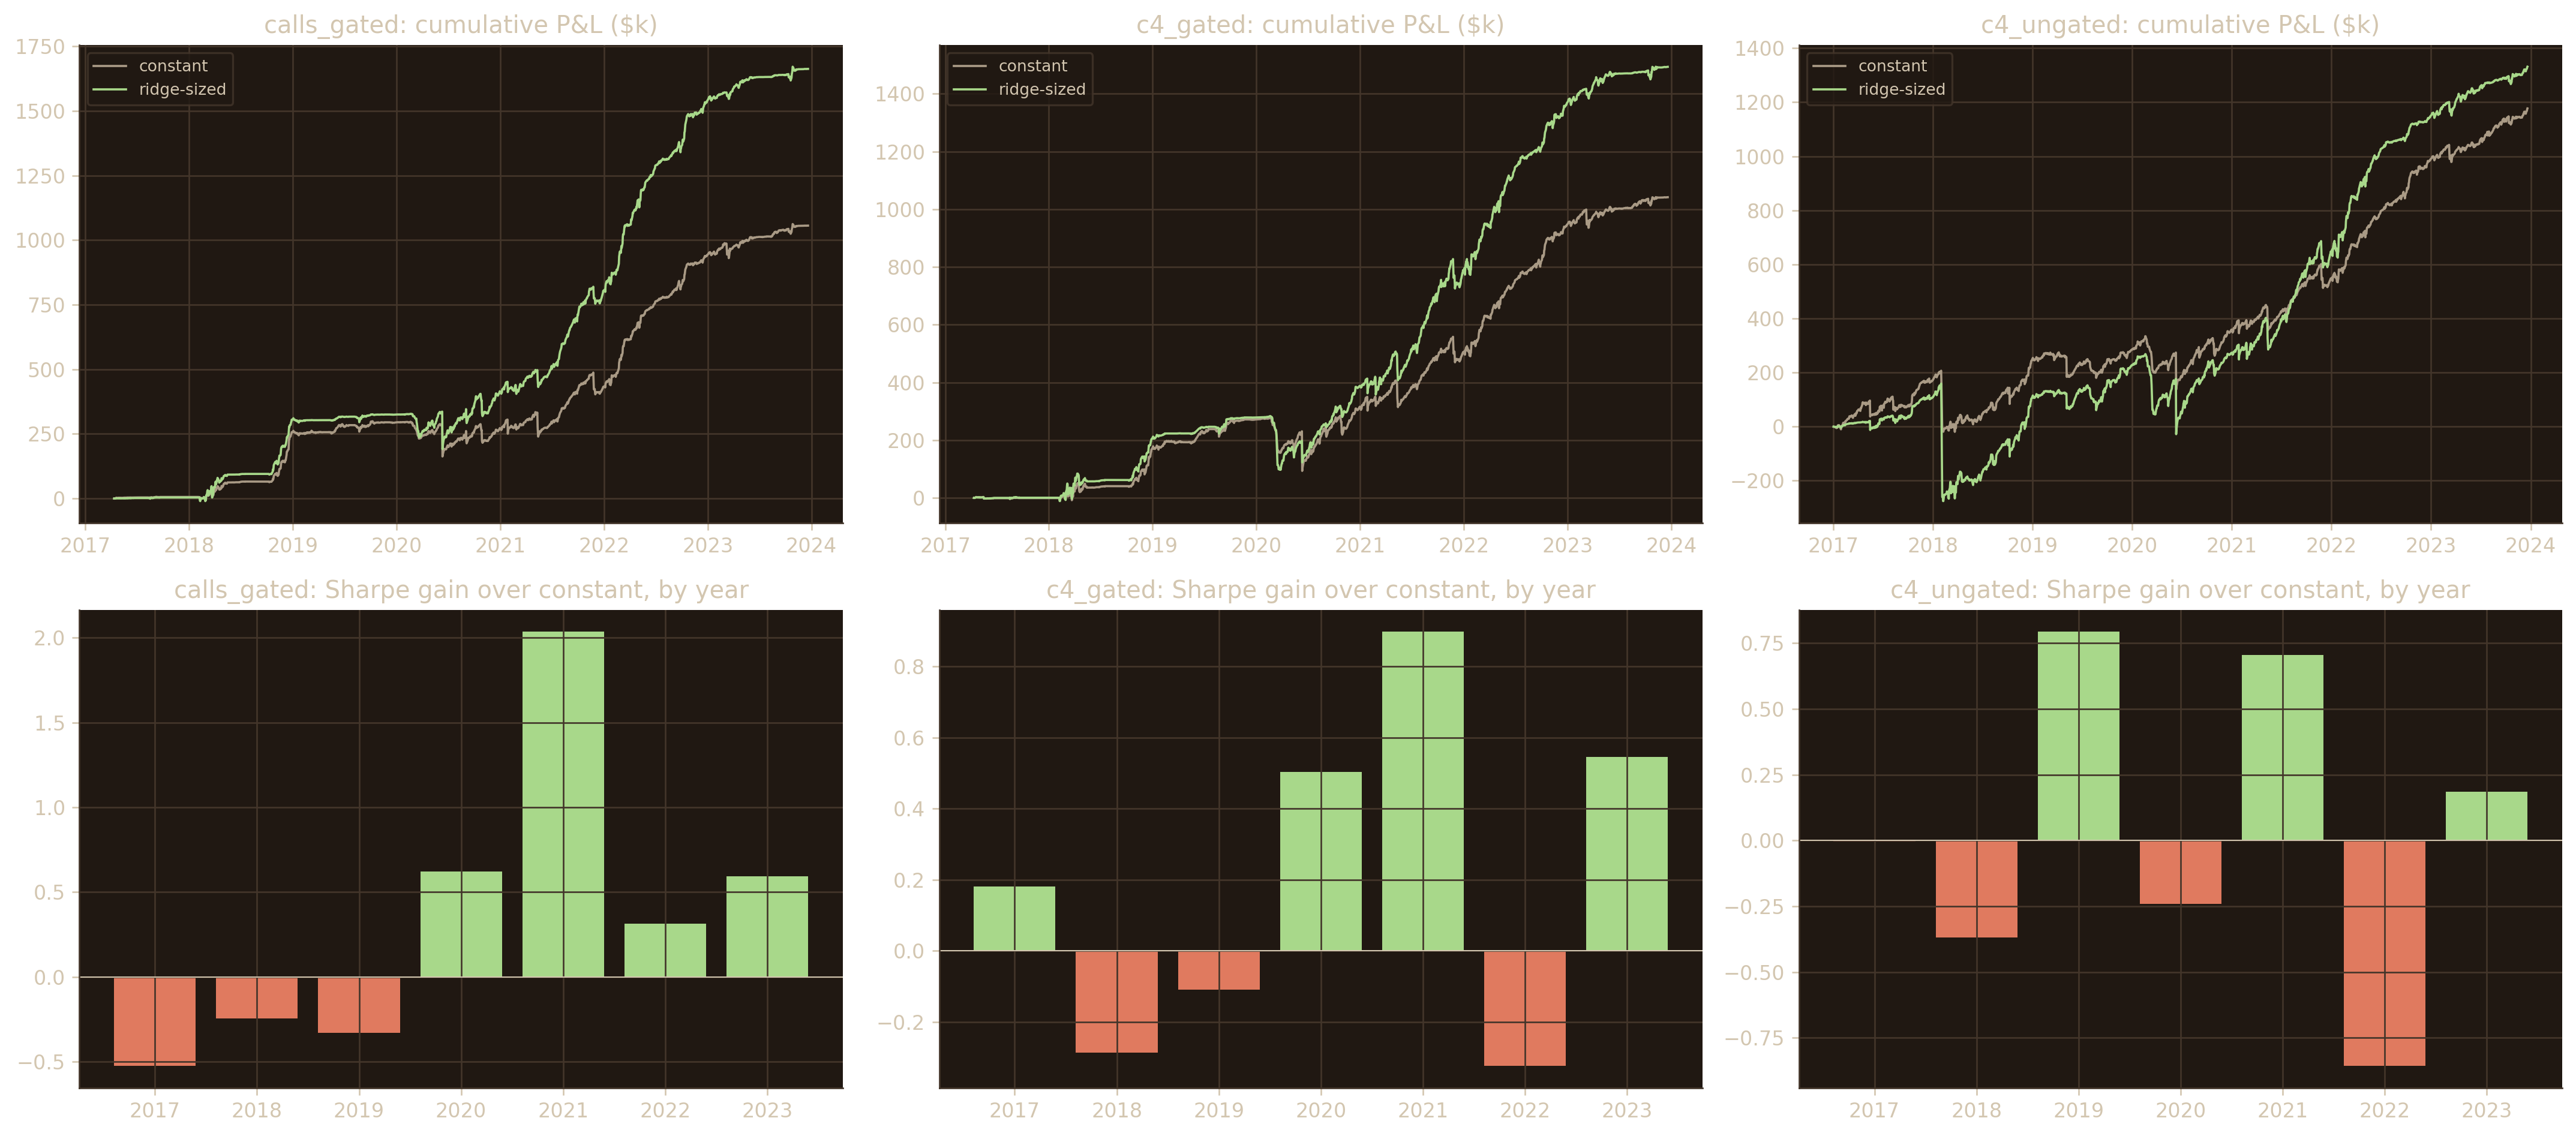

shape: (3, 7)
┌─────────────┬──────────┬───────┬───────┬────────────────┬──────────────┬───────┐
│ universe    ┆ constant ┆ ridge ┆ gain  ┆ ci99           ┆ years_better ┆ years │
│ ---         ┆ ---      ┆ ---   ┆ ---   ┆ ---            ┆ ---          ┆ ---   │
│ str         ┆ f64      ┆ f64   ┆ f64   ┆ str            ┆ u32          ┆ u32   │
╞═════════════╪══════════╪═══════╪═══════╪════════════════╪══════════════╪═══════╡
│ c4_gated    ┆ 1.57     ┆ 2.04  ┆ 0.46  ┆ [-0.24, +1.16] ┆ 4            ┆ 7     │
│ c4_ungated  ┆ 1.26     ┆ 0.97  ┆ -0.28 ┆ [-0.68, +0.49] ┆ 3            ┆ 7     │
│ calls_gated ┆ 1.72     ┆ 2.36  ┆ 0.64  ┆ [+0.15, +1.18] ┆ 4            ┆ 7     │
└─────────────┴──────────┴───────┴───────┴────────────────┴──────────────┴───────┘


In [2]:
rows, yrows = [], []
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for j, case in enumerate(CASES):
    r = books.filter((pl.col("case") == case) & (pl.col("book") == "ridge")).sort("date")
    c = books.filter((pl.col("case") == case) & (pl.col("book") == "constant")).sort("date")
    both = r.join(c, on="date", suffix="_c").sort("date")
    d, lo, hi = paired_sharpe_diff(both["pnl_c"].to_numpy(), both["pnl"].to_numpy())
    rows.append({"universe": case, "constant": sharpe(both["pnl_c"]), "ridge": sharpe(both["pnl"]), "gain": d, "ci99": f"[{lo:+.2f}, {hi:+.2f}]"})
    for (y,), g in both.group_by(pl.col("date").dt.year()):
        yrows.append({"universe": case, "year": y, "gain": sharpe(g["pnl"]) - sharpe(g["pnl_c"])})
    ax[0, j].plot(both["date"], np.cumsum(both["pnl_c"].to_numpy()) / 1e3, color="#a99a85", lw=1.1, label="constant")
    ax[0, j].plot(both["date"], np.cumsum(both["pnl"].to_numpy()) / 1e3, color=GAIN, lw=1.1, label="ridge-sized")
    ax[0, j].set_title(f"{case}: cumulative P&L ($k)"); ax[0, j].legend(fontsize=8)
yr = pl.DataFrame(yrows).sort("universe", "year")
for j, case in enumerate(CASES):
    s = yr.filter(pl.col("universe") == case)
    ax[1, j].bar(s["year"], s["gain"], color=[GAIN if v > 0 else LOSS for v in s["gain"]]); ax[1, j].axhline(0, color=INK, lw=0.6)
    ax[1, j].set_title(f"{case}: Sharpe gain over constant, by year")
plt.tight_layout(); plt.show()
print(pl.DataFrame(rows).join(yr.group_by("universe").agg(years_better=(pl.col("gain") > 0).sum(), years=pl.len()), on="universe"))

**Conclusion.**
- **Inside the gate, the ridge beats constant size**, more on the call wing alone than on the full structure. Only the
  call wing's CI excludes zero.
- **The gain rests on a few years.** Both gated books win in about half of the test years and trail in the early ones.
- **Without the gate, the ridge loses to constant size.**

## 2. What the prediction ranks

**How to read.** Every out-of-sample entry sorted into five equal groups by its prediction, within each universe. Per
group: the mean final P&L per entry, the share of entries that hit the stop, and the mean size the rank rule gave it.
For a short-premium book, a useful sizing model shows a falling stop rate and a rising P&L.

shape: (15, 6)
┌─────────────┬───────┬─────────┬──────────┬───────────┬───────────┐
│ case        ┆ fifth ┆ entries ┆ mean_pnl ┆ stop_rate ┆ mean_size │
│ ---         ┆ ---   ┆ ---     ┆ ---      ┆ ---       ┆ ---       │
│ str         ┆ i8    ┆ u32     ┆ f64      ┆ f64       ┆ f64       │
╞═════════════╪═══════╪═════════╪══════════╪═══════════╪═══════════╡
│ c4_gated    ┆ 1     ┆ 187     ┆ 375.96   ┆ 0.12      ┆ 0.30      │
│ c4_gated    ┆ 2     ┆ 188     ┆ 806.63   ┆ 0.10      ┆ 0.82      │
│ c4_gated    ┆ 3     ┆ 187     ┆ 1118.36  ┆ 0.08      ┆ 1.28      │
│ c4_gated    ┆ 4     ┆ 188     ┆ 1516.52  ┆ 0.02      ┆ 1.62      │
│ c4_gated    ┆ 5     ┆ 188     ┆ 1730.67  ┆ 0.02      ┆ 1.90      │
│ c4_ungated  ┆ 1     ┆ 285     ┆ 849.49   ┆ 0.06      ┆ 0.33      │
│ c4_ungated  ┆ 2     ┆ 286     ┆ 615.27   ┆ 0.13      ┆ 0.74      │
│ c4_ungated  ┆ 3     ┆ 286     ┆ 736.26   ┆ 0.12      ┆ 1.16      │
│ c4_ungated  ┆ 4     ┆ 286     ┆ 1165.79  ┆ 0.06      ┆ 1.54      │
│ c4_ungated  ┆ 5  

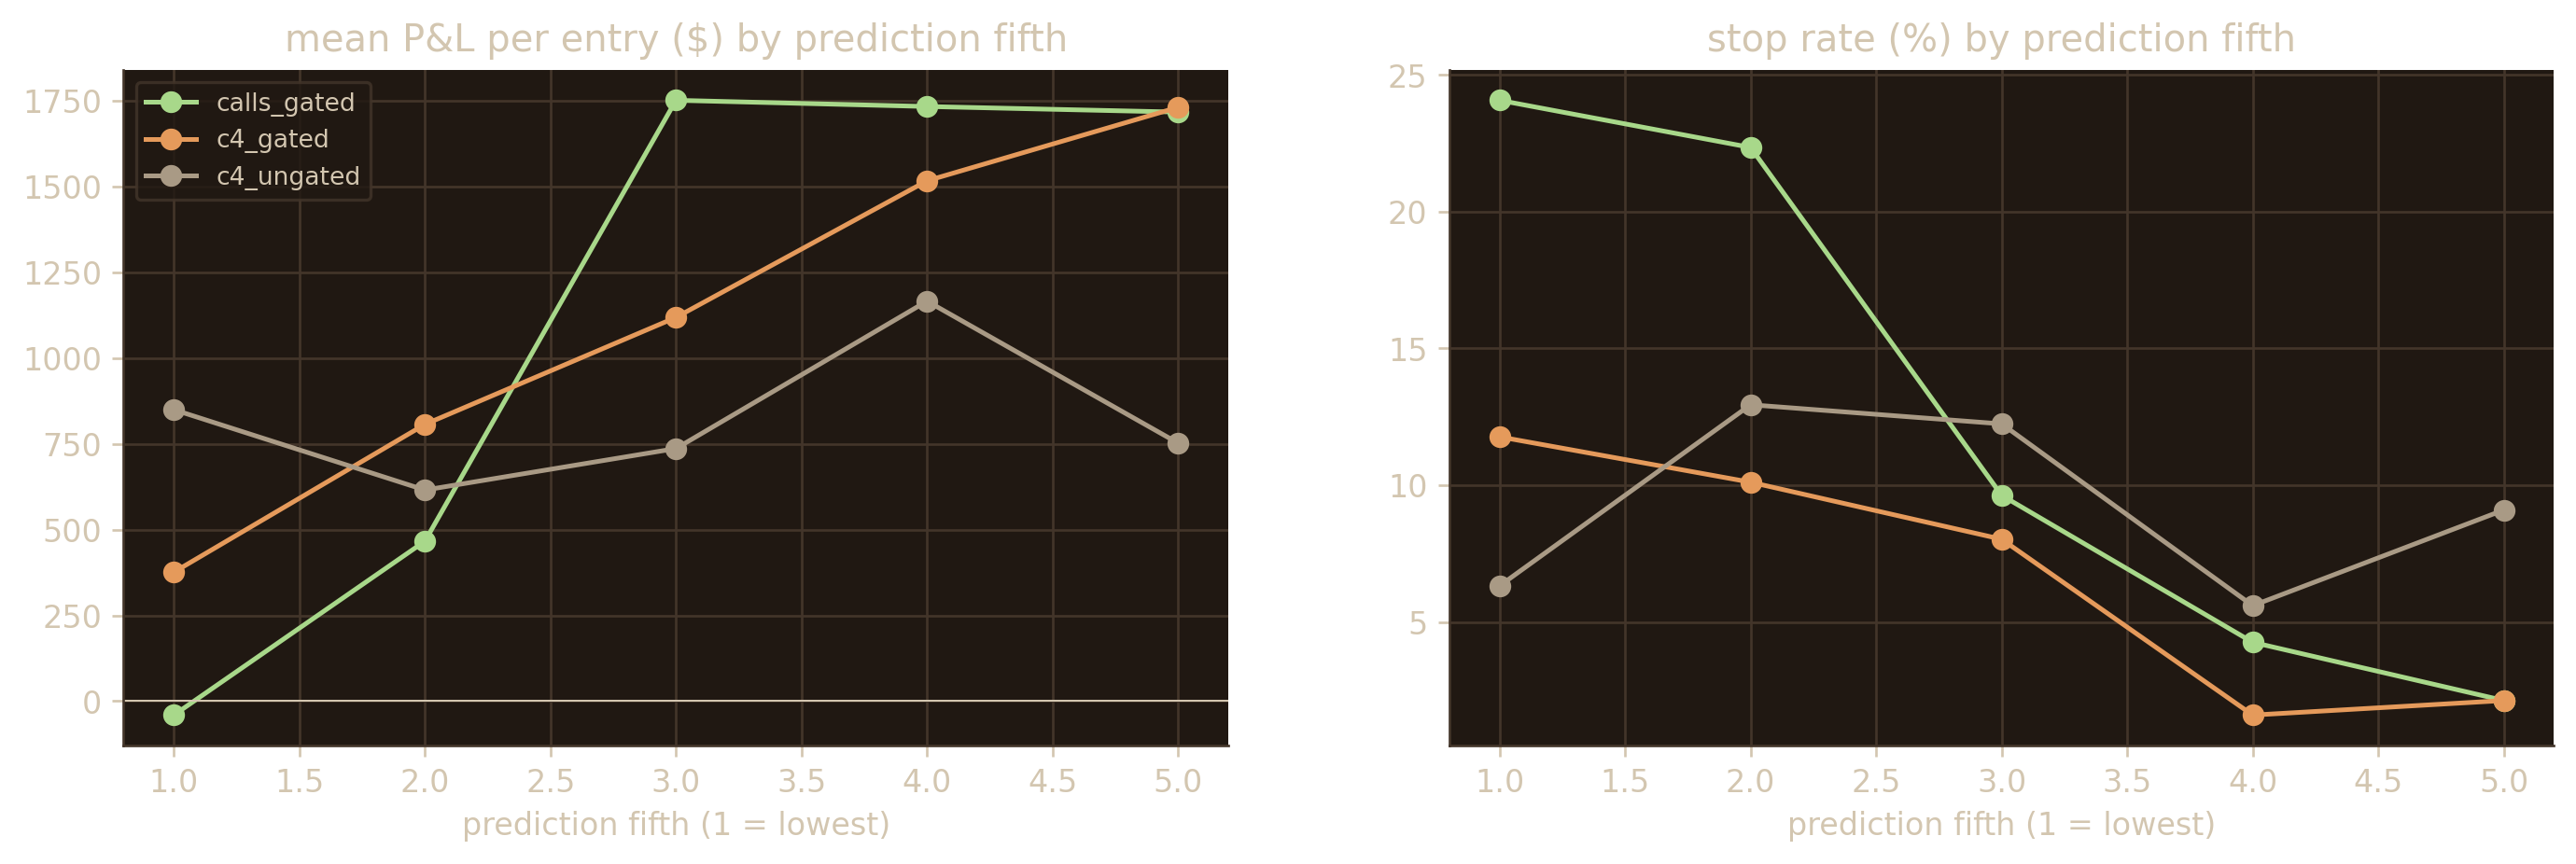

In [3]:
q = oos.with_columns(fifth=((pl.col("pred").rank().over("case") / pl.len().over("case")) * 5).ceil().clip(1, 5).cast(pl.Int8))
t = q.group_by("case", "fifth").agg(entries=pl.len(), mean_pnl=pl.col("y").mean(), stop_rate=pl.col("stopped").mean(), mean_size=pl.col("w").mean()).sort("case", "fifth")
print(t)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for case in CASES:
    s = t.filter(pl.col("case") == case)
    ax[0].plot(s["fifth"], s["mean_pnl"], marker="o", color=COLS[case], label=case)
    ax[1].plot(s["fifth"], s["stop_rate"] * 100, marker="o", color=COLS[case], label=case)
ax[0].axhline(0, color=INK, lw=0.6); ax[0].set_title("mean P&L per entry ($) by prediction fifth"); ax[0].set_xlabel("prediction fifth (1 = lowest)")
ax[1].set_title("stop rate (%) by prediction fifth"); ax[1].set_xlabel("prediction fifth (1 = lowest)"); ax[0].legend(fontsize=8)
plt.show()

**Conclusion.**
- **Inside the gate, the prediction sorts the stops.** The stop rate falls steeply from the lowest fifth to the
  highest, and the mean P&L rises with it, flat from the middle fifth up. The model mostly learns which entries get run
  over.
- **Without the gate there is no order.** The lowest fifth earns about as much as the highest.

## 3. What the ridge learned

**How to read.** Each fold's standardised coefficients ($ of predicted entry P&L per standard deviation of the
input), averaged over the seven folds, with the share of folds that agree with the average's sign. Then the gated call
wing fold by fold: an input whose colour flips across folds is not a stable input.

== calls_gated
shape: (10, 4)
┌─────────────┬─────────┬────────┬───────────┐
│ feature     ┆ mean    ┆ sd     ┆ same_sign │
│ ---         ┆ ---     ┆ ---    ┆ ---       │
│ str         ┆ f64     ┆ f64    ┆ f64       │
╞═════════════╪═════════╪════════╪═══════════╡
│ spx_dd252   ┆ -669.74 ┆ 100.74 ┆ 1.00      │
│ rv63        ┆ -559.60 ┆ 187.99 ┆ 1.00      │
│ smile       ┆ 448.50  ┆ 144.47 ┆ 1.00      │
│ vix_ret21   ┆ -441.19 ┆ 131.05 ┆ 1.00      │
│ dte         ┆ 424.10  ┆ 186.80 ┆ 1.00      │
│ cpi_in_hold ┆ -412.52 ┆ 208.62 ┆ 1.00      │
│ credit_pct  ┆ 331.48  ┆ 130.88 ┆ 1.00      │
│ vix_z252    ┆ -287.25 ┆ 169.05 ┆ 1.00      │
│ spx_ret21   ┆ -278.19 ┆ 79.66  ┆ 1.00      │
│ spx_rv21    ┆ 262.98  ┆ 101.64 ┆ 1.00      │
└─────────────┴─────────┴────────┴───────────┘
== c4_gated
shape: (10, 4)
┌──────────────────┬─────────┬────────┬───────────┐
│ feature          ┆ mean    ┆ sd     ┆ same_sign │
│ ---              ┆ ---     ┆ ---    ┆ ---       │
│ str              ┆ f64     ┆ f64 

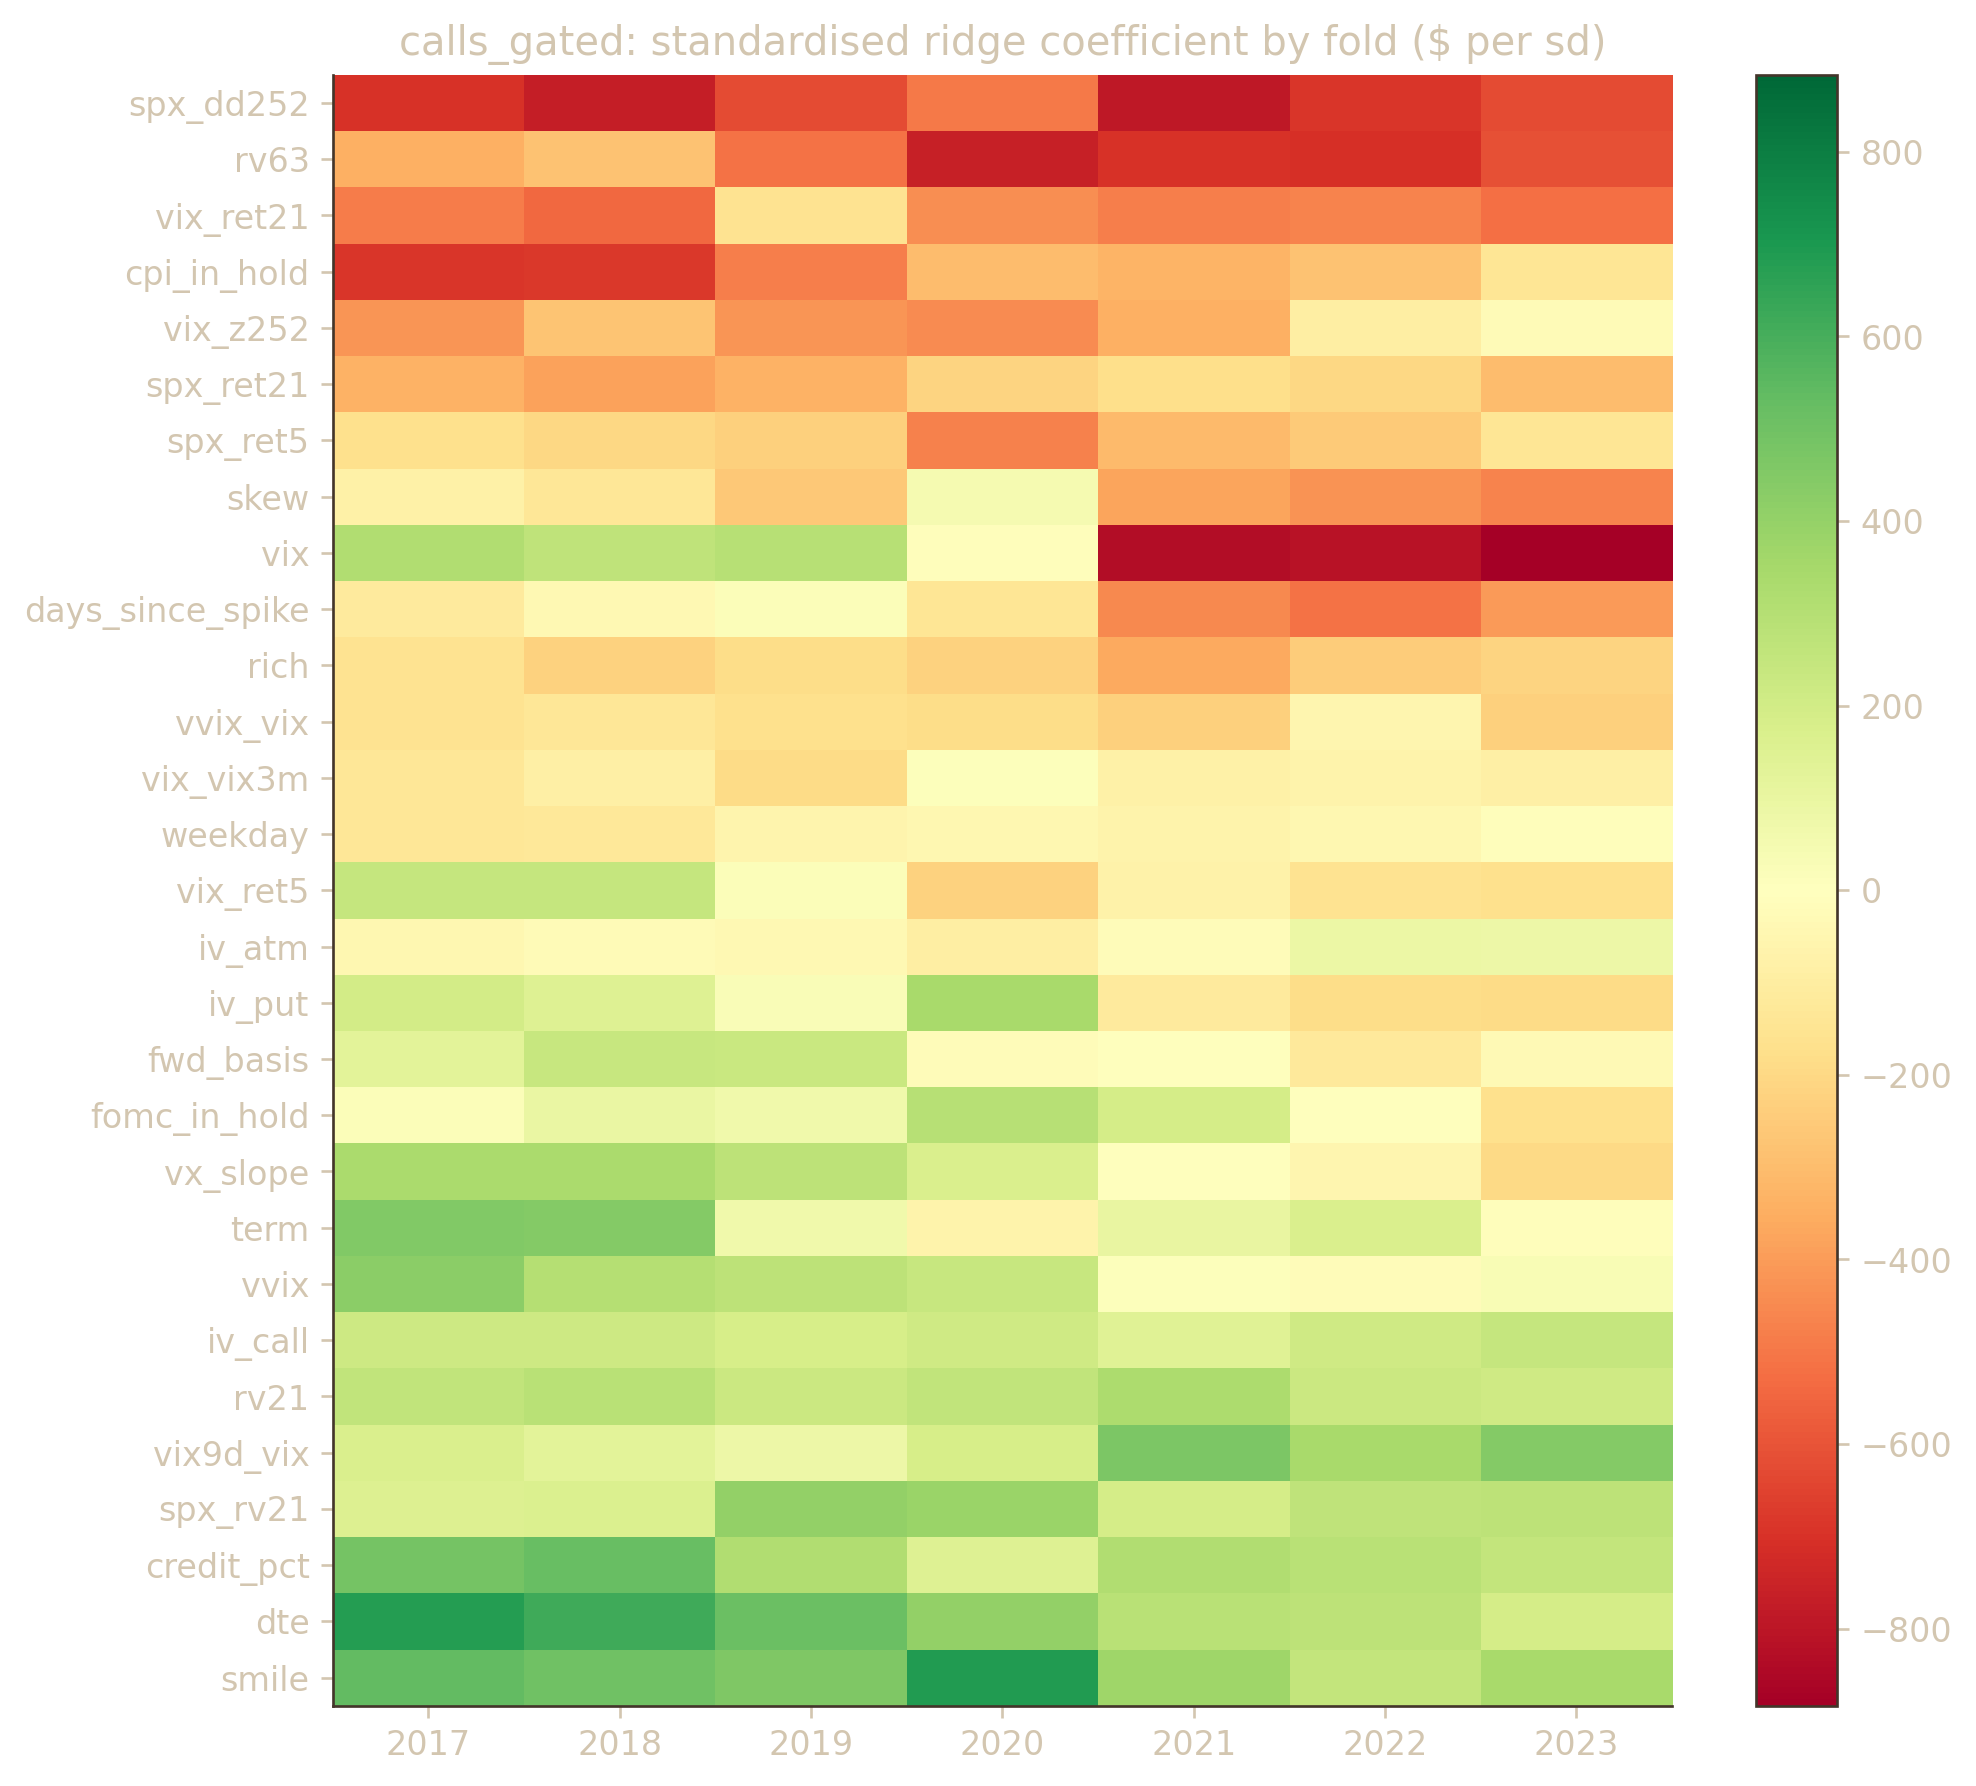

In [4]:
for case in CASES:
    t = (coefs.filter(pl.col("case") == case).group_by("feature")
         .agg(mean=pl.col("coef").mean(), sd=pl.col("coef").std(), same_sign=(pl.col("coef").sign() == pl.col("coef").mean().sign()).mean())
         .with_columns(abs=pl.col("mean").abs()).sort("abs", descending=True).drop("abs"))
    print("==", case); print(t.head(10))
c = coefs.filter(pl.col("case") == "calls_gated")
order = c.group_by("feature").agg(m=pl.col("coef").mean()).sort("m")["feature"].to_list()
M = pl.DataFrame({"feature": order}).join(c.pivot(on="fold", index="feature", values="coef"), on="feature", how="left")
folds = [x for x in M.columns if x != "feature"]
V = M.select(folds).to_numpy(); lim = np.abs(V).max()
fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(V, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(order)), order); ax.set_xticks(range(len(folds)), folds); ax.grid(False)
ax.set_title("calls_gated: standardised ridge coefficient by fold ($ per sd)"); plt.colorbar(im, ax=ax); plt.show()

**Conclusion.**
- **Inside the gate the ridge reads stress and calm, with stable signs.** It sizes up after an SPX drawdown and when
  the call wing is rich against the at-the-money (the smile). It sizes down after a quarter of volatile VIX, after a
  VIX rise over the past month, and when a CPI release falls inside the hold.
- **The VIX level is not a stable input once the gate is on.** Its sign changes across folds.

## 4. In-sample against out-of-sample

**How to read.** Each fold's rank correlation between prediction and outcome on its own training rows (in-sample)
against the same on its test year (out-of-sample). Entries overlap for about a month, so a fold's independent sample
is roughly its training entries divided by 21.

shape: (21, 6)
┌──────┬───────┬────────────┬────────┬─────────────┬────────────────────┐
│ year ┆ is_ic ┆ train_rows ┆ oos_ic ┆ case        ┆ independent_months │
│ ---  ┆ ---   ┆ ---        ┆ ---    ┆ ---         ┆ ---                │
│ i64  ┆ f64   ┆ i64        ┆ f64    ┆ str         ┆ f64                │
╞══════╪═══════╪════════════╪════════╪═════════════╪════════════════════╡
│ 2017 ┆ 0.77  ┆ 176        ┆ 0.75   ┆ c4_gated    ┆ 8.00               │
│ 2018 ┆ 0.78  ┆ 189        ┆ 0.04   ┆ c4_gated    ┆ 9.00               │
│ 2019 ┆ 0.65  ┆ 269        ┆ 0.59   ┆ c4_gated    ┆ 13.00              │
│ 2020 ┆ 0.65  ┆ 380        ┆ 0.37   ┆ c4_gated    ┆ 18.00              │
│ 2021 ┆ 0.60  ┆ 555        ┆ 0.53   ┆ c4_gated    ┆ 26.00              │
│ 2022 ┆ 0.60  ┆ 760        ┆ 0.05   ┆ c4_gated    ┆ 36.00              │
│ 2023 ┆ 0.61  ┆ 967        ┆ 0.21   ┆ c4_gated    ┆ 46.00              │
│ 2017 ┆ 0.68  ┆ 373        ┆ -0.08  ┆ c4_ungated  ┆ 18.00              │
│ 2018 ┆ 0.52  ┆ 573   

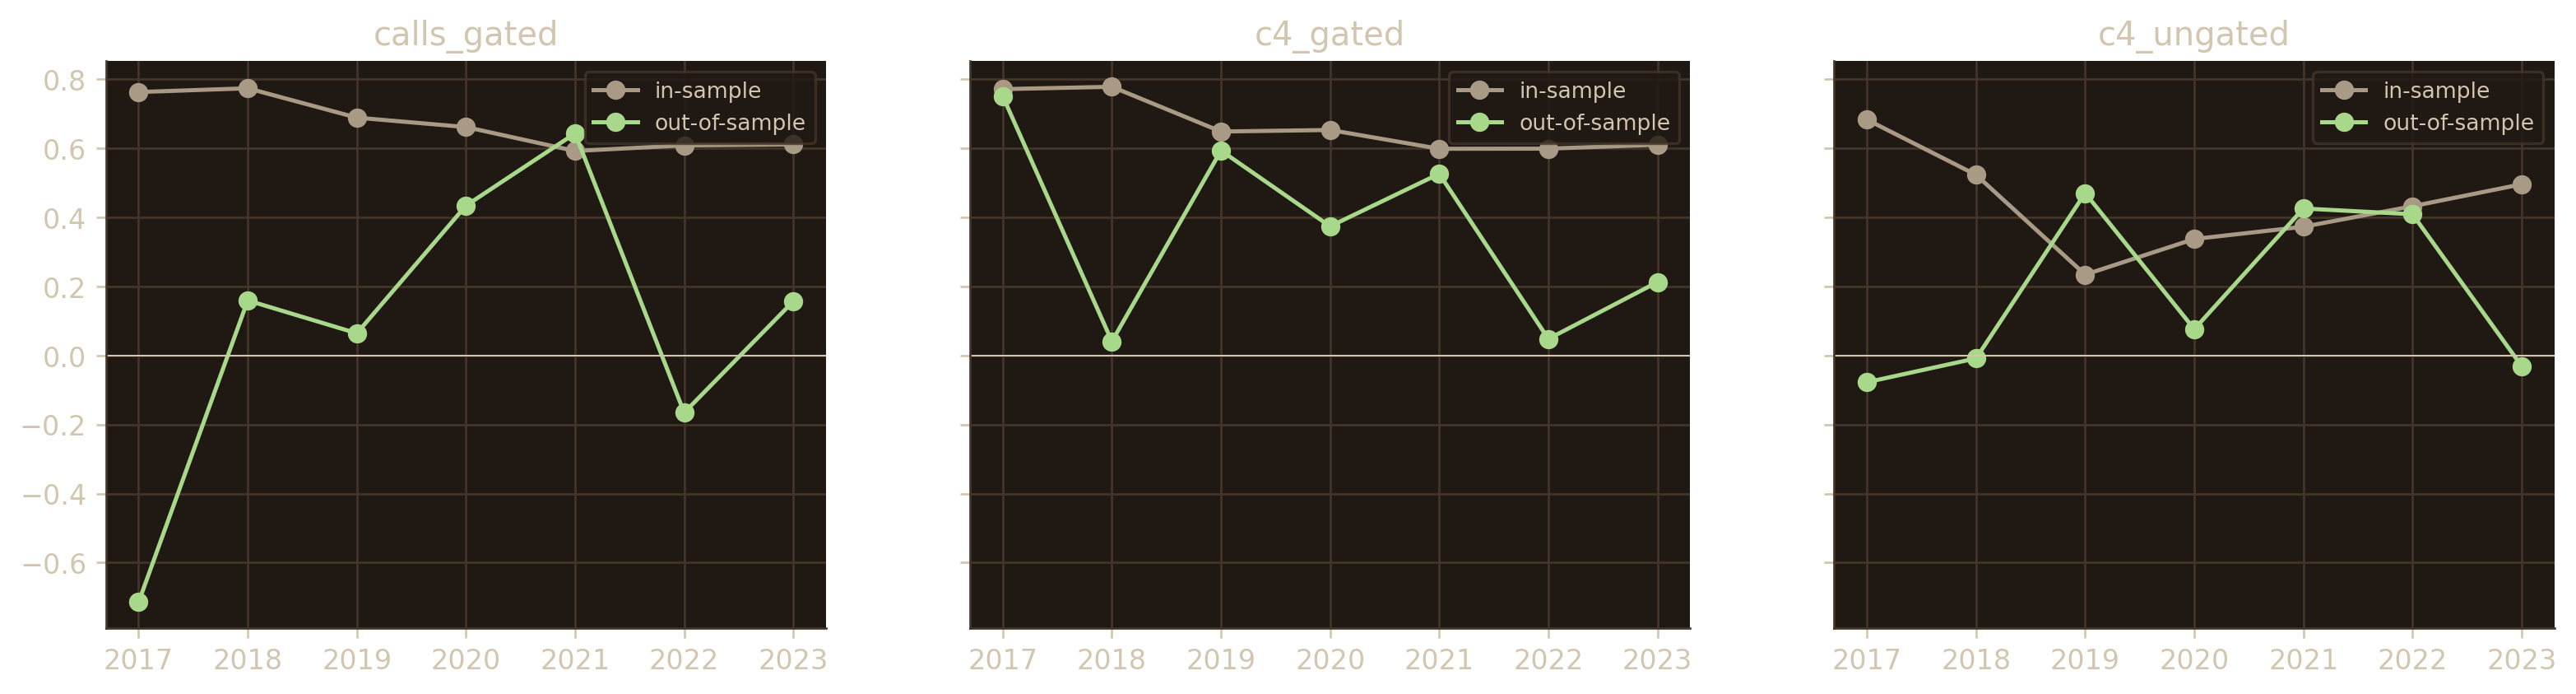

In [5]:
rows = []
for case in CASES:
    o = oos.filter(pl.col("case") == case).with_columns(year=pl.col("t0").dt.year())
    ic = o.group_by("year").agg(oos_ic=pl.corr("pred", "y", method="spearman"))
    f = coefs.filter(pl.col("case") == case).group_by("fold").agg(pl.col("is_ic").first(), pl.col("train_rows").first()).rename({"fold": "year"})
    rows.append(f.join(ic, on="year").with_columns(case=pl.lit(case), independent_months=(pl.col("train_rows") / 21).round(0)))
t = pl.concat(rows).sort("case", "year"); print(t)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for a_, case in zip(ax, CASES):
    s = t.filter(pl.col("case") == case)
    a_.plot(s["year"], s["is_ic"], marker="o", color="#a99a85", label="in-sample"); a_.plot(s["year"], s["oos_ic"], marker="o", color=GAIN, label="out-of-sample")
    a_.axhline(0, color=INK, lw=0.6); a_.set_title(case); a_.legend(fontsize=8)
plt.show()

**Conclusion.**
- **The fit is mostly noise.** The in-sample correlation is high in every fold; out of sample it swings from strongly
  negative to strongly positive from year to year.
- **The samples are too small for 29 inputs.** Inside the gate a fold trains on a few dozen independent months at
  most. The stable signs of section 3 are therefore not yet stable skill.

## Conclusion

- **No ML sizing is adopted.** The gated call-wing ridge has the right signs and an economic story, but its gain holds
  in about half of the test years, its in-sample fit far exceeds its out-of-sample fit, and many books were evaluated in
  the search that found it.
- **What chairlift confirmed is mogul's hand-found economics:** the VIX gate, the call-heavy structure, a stop, and
  smaller size in persistent vol-of-vol.
- **If one ML candidate is carried forward,** it is the gated call-wing ridge as a sizing overlay, registered now and
  judged once, on its gain over constant size, on data it has not seen.